# Beyond Fisher: DALI Forecasts with psiphy

A Fisher forecast treats the mean data vector as **linear** in the parameters over
the width of the posterior, so the forecast posterior is always a Gaussian ellipse.
When the data respond non-linearly, the true posterior is skewed or curved, and the
Fisher ellipse can be misplaced, too small or too large.

DALI (*Derivative Approximation for LIkelihoods*, [Sellentin, Quartin & Amendola 2014](https://arxiv.org/abs/1401.6892))
keeps higher-order derivatives of the mean in the Taylor expansion. With
$\Delta = \theta - \theta_{\rm fid}$,

$$r(\Delta) = \mu_{,a}\Delta_a + \tfrac12 \mu_{,ab}\Delta_a\Delta_b + \tfrac16 \mu_{,abc}\Delta_a\Delta_b\Delta_c ,
\qquad \ln L = -\tfrac12\, r^{\rm T} C^{-1} r .$$

Keeping only the first term gives the Fisher matrix. Up to the second term is the **doublet** (DALI-2), and up to
the third is the **triplet** (DALI-3). Because $-\ln L$ is a squared norm, every truncation stays
normalisable, which a direct Taylor expansion of $\ln L$ would not.

`psiphy.forecasting.FisherMatrixDALI` extends `FisherMatrix`. The workflow is the
[Fisher tutorial](fisher_analysis.ipynb) plus one step:

1. Estimate the covariance and the first derivatives, and compute the Fisher matrix, as before
2. Estimate the higher-order derivatives with `estimate_dali_derivatives`
3. Sample the DALI posterior with `sample` or `to_getdist`

We compare the result with the exact posterior of a toy model.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import getdist.chains
from getdist import MCSamples, plots

from psiphy.forecasting import FisherMatrixDALI
from psiphy.mcmc import MHSampler
from psiphy.toy_models import PowerLawSpectrum

np.random.seed(42)
getdist.chains.print_load_details = False   # quieter getdist

## 1. A non-linear toy simulator

`PowerLawSpectrum` models band powers of a power-law spectrum,

$$C_\ell = A_{\rm s} \left(\ell / \ell_{\rm pivot}\right)^{n_{\rm s} - 1} .$$

The band powers are linear in $A_{\rm s}$ but exponential in $n_{\rm s}$. Over the
2.3 decades in $\ell$, a change $\delta n_{\rm s}$ rescales the band powers by
$\exp[\delta n_{\rm s} \ln(\ell/\ell_{\rm pivot})]$. That factor is far from
linear when the noise lets $n_{\rm s}$ wander by a few tenths. We use 10 band powers
with Gaussian noise of standard deviation 0.5.

As in the Fisher tutorial, the simulator takes `(theta, initial_seed, noise_seed)`.
A given pair of seeds gives the same noise realisation at every `theta`, and
`noise_seed=0` is noiseless.

In [2]:
model = PowerLawSpectrum(ells=np.geomspace(10, 2000, 10), noise_sigma=0.5)


def mean_spectrum(theta):
    '''Mean band powers; theta has shape (2,) or (n, 2).'''
    A_s, n_s = np.moveaxis(np.asarray(theta, dtype=float), -1, 0)
    return np.asarray(A_s)[..., None] * (model.ells / model.ell_pivot) ** (np.asarray(n_s)[..., None] - 1)


def make_simulator(noise):
    def simulator(theta, initial_seed, noise_seed):
        x = mean_spectrum(theta)
        if noise_seed:
            x = x + np.random.default_rng(1000 * initial_seed + noise_seed).normal(0, noise, x.size)
        return x
    return simulator


simulator   = make_simulator(model.noise_sigma)
theta_fid   = np.array([1.0, 1.0])
param_names = model.param_names
label_names = {'A_s': r'A_{\rm s}', 'n_s': r'n_{\rm s}'}

The plot shows the spectrum at $n_{\rm s} = 1 \pm 0.2$ (about $2\sigma$ in the
Fisher forecast below). The dashed lines are the linear extrapolation that the
Fisher matrix assumes. At high $\ell$ the true response bends away from it.

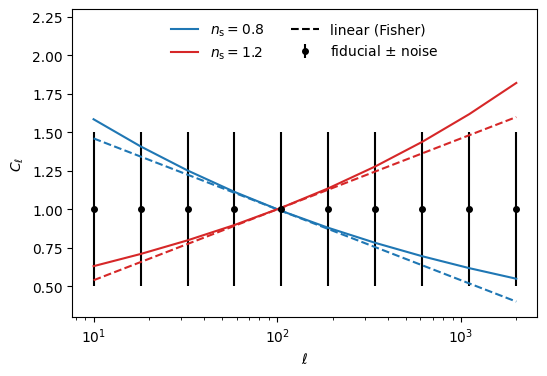

In [3]:
ells = model.ells
dmu_dns = mean_spectrum(theta_fid) * np.log(ells / model.ell_pivot)

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(ells, mean_spectrum(theta_fid), yerr=model.noise_sigma, fmt='ko', ms=4,
            label=r'fiducial $\pm$ noise')
for dn, c in [(-0.2, 'C0'), (0.2, 'C3')]:
    ax.plot(ells, mean_spectrum([1.0, 1.0 + dn]), c=c, label=rf'$n_{{\rm s}} = {1 + dn:.1f}$')
    ax.plot(ells, mean_spectrum(theta_fid) + dn * dmu_dns, c=c, ls='--')
ax.plot([], [], 'k--', label='linear (Fisher)')
ax.set_xscale('log')
ax.set_xlabel(r'$\ell$')
ax.set_ylabel(r'$C_\ell$')
ax.set_ylim(0.3, 2.3)
ax.legend(frameon=False, loc='upper center', ncol=2)
plt.show()

## 2. Covariance, first derivatives and Fisher matrix

These steps are inherited from `FisherMatrix` and work exactly as in the Fisher tutorial.

In [4]:
fm = FisherMatrixDALI(simulator, theta_fid, param_names, verbose=True)
fm.estimate_covariance(seeds=range(1, 51), noise_seeds=range(1, 11))
fm.estimate_derivatives(delta_frac=0.01, seeds=[1], noise_seed=0)
fm.compute();


  Estimating covariance matrix


  Total realisations: 500, data points: 10
  Hartlap factor: 0.978
  Condition number: 1.66e+00


  Computing derivatives (2-point stencil)


  A_s: |dmu/dtheta| = 3.1623


  n_s: |dmu/dtheta| = 5.4588


  Fisher Matrix Results  [standard]

[[ 39.86986517  14.98228565]
 [ 14.98228565 125.74631052]]

  --- 1D marginal errors ---
    A_s: 0.1620  (16.2%)
    n_s: 0.0912  (9.1%)

  --- 2D marginal errors ---
    (A_s, n_s): sigma_A_s=0.1620, sigma_n_s=0.0912

  --- Conditional errors (others fixed) ---
    A_s: 0.1584  (15.8%)
    n_s: 0.0892  (8.9%)

  --- Correlations ---
    corr(A_s, n_s): -0.212



## 3. Higher-order derivatives

`estimate_dali_derivatives(order=...)` estimates $\mu_{,ab}$ (`order=2`), or both
$\mu_{,ab}$ and $\mu_{,abc}$ (`order=3`), with central finite differences.
Each partial derivative is a product of 1D central stencils, one for each distinct
parameter. For example, at `accuracy=2`,

$$\mu_{,ab} \approx \frac{\mu_{++} - \mu_{+-} - \mu_{-+} + \mu_{--}}{4 h_a h_b},
\qquad \mu_{,aa} \approx \frac{\mu_{+} - 2\mu_0 + \mu_{-}}{h_a^2}.$$

`accuracy` sets the truncation error $O(h^{\rm accuracy})$; higher accuracy needs more
stencil points. The method reports how many new simulations it needs before running them.
Points shared with `estimate_derivatives` (same step) or with the covariance runs come from the cache.

We use noiseless derivatives (`noise_seed=0`). Two seeds are the minimum for the noise
check in section 5.

In [5]:
fm.estimate_dali_derivatives(order=3, delta_frac=0.02, seeds=[1, 2], noise_seed=0);


  Computing DALI derivatives (order 3, O(h^2) stencils)
  13 stencil points x 2 seeds x 1 noise seeds: 26 new simulations


  d(A_s)(A_s): |d^2mu| = 0.0000


  d(A_s)(n_s): |d^2mu| = 5.4603


  d(n_s)(n_s): |d^2mu| = 12.8839


  d(A_s)(A_s)(A_s): |d^3mu| = 0.0000


  d(A_s)(A_s)(n_s): |d^3mu| = 0.0000


  d(A_s)(n_s)(n_s): |d^3mu| = 12.8839


  d(n_s)(n_s)(n_s): |d^3mu| = 33.6914



For this model the derivatives are known analytically. With $P = (\ell/\ell_{\rm pivot})^{n_{\rm s}-1}$ and
$L = \ln(\ell/\ell_{\rm pivot})$, the non-zero ones are
$\mu_{,A n} = PL$, $\mu_{,nn} = A P L^2$, $\mu_{,Ann} = PL^2$ and $\mu_{,nnn} = A P L^3$.

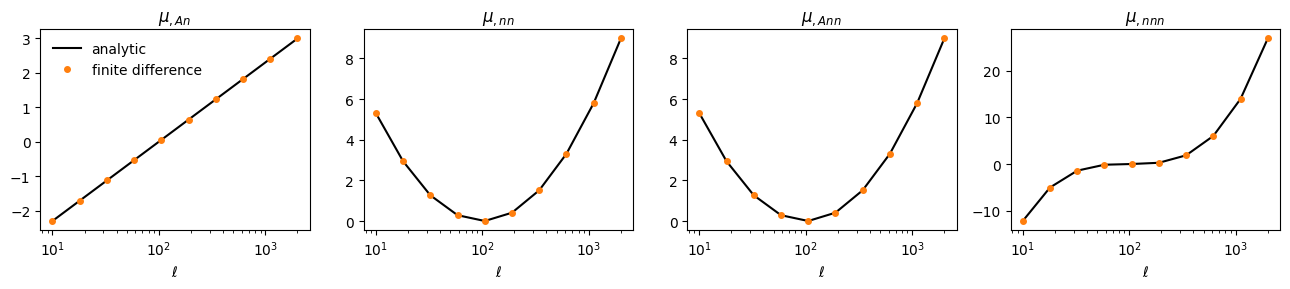

$\mu_{,A n}$     max relative error: 6.0e-04
$\mu_{,nn}$      max relative error: 3.0e-04
$\mu_{,Ann}$     max relative error: 3.0e-04
$\mu_{,nnn}$     max relative error: 9.0e-04
mu_,AA, mu_,AAA, mu_,AAn (zero): 0.0 0.0 1.3877787807814455e-11


In [6]:
A, n = theta_fid
P, L = (ells / model.ell_pivot) ** (n - 1), np.log(ells / model.ell_pivot)
analytic = {
    r'$\mu_{,A n}$':   (fm.d2mu_dtheta[0, 1],    P * L),
    r'$\mu_{,nn}$':    (fm.d2mu_dtheta[1, 1],    A * P * L**2),
    r'$\mu_{,Ann}$':   (fm.d3mu_dtheta[0, 1, 1], P * L**2),
    r'$\mu_{,nnn}$':   (fm.d3mu_dtheta[1, 1, 1], A * P * L**3),
}

fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, (name, (num, ana)) in zip(axes, analytic.items()):
    ax.plot(ells, ana, 'k-', label='analytic')
    ax.plot(ells, num, 'C1o', ms=4, label='finite difference')
    ax.set_xscale('log')
    ax.set_xlabel(r'$\ell$')
    ax.set_title(name)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

for name, (num, ana) in analytic.items():
    print(f"{name:16s} max relative error: {np.max(np.abs(num - ana)) / np.max(np.abs(ana)):.1e}")
print("mu_,AA, mu_,AAA, mu_,AAn (zero):", np.abs(fm.d2mu_dtheta[0, 0]).max(),
      np.abs(fm.d3mu_dtheta[0, 0, 0]).max(), np.abs(fm.d3mu_dtheta[0, 0, 1]).max())

### Invalid stencils

The order and accuracy are checked, and every stencil is built, before any simulation runs.
`accuracy` must be even, because central differences cancel the odd error terms.

In [7]:
for kwargs in [dict(order=2, accuracy=3), dict(order=4)]:
    try:
        fm.estimate_dali_derivatives(**kwargs)
    except ValueError as err:
        print(f"{kwargs}: ValueError: {err}")

{'order': 2, 'accuracy': 3}: ValueError: accuracy must be an even integer >= 2 (central differences), got 3.
{'order': 4}: ValueError: order must be 2 (doublet) or 3 (triplet), got 4.


## 4. Choosing the step size

Truncation error falls as $h^{\rm accuracy}$. Rounding error grows as $\epsilon/h^k$ for a $k$-th
derivative, and simulation noise grows the same way. The best step is therefore larger
than for first derivatives, and larger still for third derivatives. We sweep `delta_frac`
and compare with the analytic derivatives.

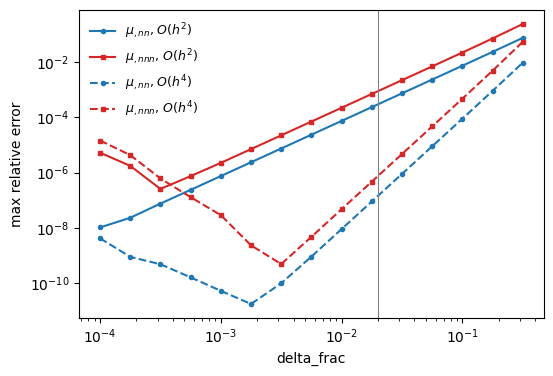

In [8]:
fm.verbose = False
delta_fracs = np.logspace(-4, -0.5, 15)
errors = {acc: {'nn': [], 'nnn': []} for acc in (2, 4)}
for acc in (2, 4):
    for df in delta_fracs:
        fm.estimate_dali_derivatives(order=3, delta_frac=df, seeds=[1, 2], noise_seed=0, accuracy=acc)
        errors[acc]['nn'].append(np.max(np.abs(fm.d2mu_dtheta[1, 1] - A * P * L**2)) / np.max(np.abs(A * P * L**2)))
        errors[acc]['nnn'].append(np.max(np.abs(fm.d3mu_dtheta[1, 1, 1] - A * P * L**3)) / np.max(np.abs(A * P * L**3)))

fig, ax = plt.subplots(figsize=(6, 4))
for acc, ls in [(2, '-'), (4, '--')]:
    ax.loglog(delta_fracs, errors[acc]['nn'],  'C0' + ls, marker='o', ms=3, label=rf'$\mu_{{,nn}}$, $O(h^{acc})$')
    ax.loglog(delta_fracs, errors[acc]['nnn'], 'C3' + ls, marker='s', ms=3, label=rf'$\mu_{{,nnn}}$, $O(h^{acc})$')
ax.axvline(0.02, c='gray', lw=0.8)
ax.set_xlabel('delta_frac')
ax.set_ylabel('max relative error')
ax.legend(frameon=False, fontsize=9)
plt.show()

# back to the chosen step (all simulations are cached)
fm.estimate_dali_derivatives(order=3, delta_frac=0.02, seeds=[1, 2], noise_seed=0);

On the right of each curve the truncation error dominates (slope 2 or 4). On the left,
rounding errors take over, and they hit the third derivatives at a larger step than
the second. `delta_frac=0.02` (grey line) sits where both are accurate. For a simulator
with noise, the noise also scales as $1/h^k$, which pushes the best step larger.

## 5. Simulation noise in higher derivatives

Real simulators are stochastic, and finite differences amplify noise by $1/h^2$ (or
$1/h^3$). The cure is **common random numbers**. `FisherMatrixDALI` gives the simulator
the same `(seed, noise_seed)` at every stencil point, so if the simulator turns those seeds
into the same realisation at every `theta`, the noise cancels in the differences.
Our simulator does this. The derivatives from noisy runs agree with the noiseless ones:

In [9]:
d2_noiseless = fm.d2mu_dtheta.copy()
fm.estimate_dali_derivatives(order=2, delta_frac=0.02, seeds=range(1, 4), noise_seeds=[1, 2])
print("max |noisy - noiseless|:", np.abs(fm.d2mu_dtheta - d2_noiseless).max())
fm.estimate_dali_derivatives(order=3, delta_frac=0.02, seeds=[1, 2], noise_seed=0);

max |noisy - noiseless|: 4.627409566637652e-13


The next simulator draws a new noise realisation whenever `theta` changes, so there are
no common random numbers. From the scatter over the seeds, `estimate_dali_derivatives`
estimates each derivative's signal-to-noise ratio, and how much its noise shifts $r$
at the Fisher $1\sigma$ offsets. It prints a warning, whatever `verbose` is, for derivatives
that are noise-dominated (SNR < `snr_warn`) **and** whose noise matters (shift > `noise_tol`).

In [10]:
def simulator_no_crn(theta, initial_seed, noise_seed):
    '''Like simulator, but the noise realisation also changes with theta.'''
    x = mean_spectrum(theta)
    if noise_seed:
        key = hash((int(initial_seed), int(noise_seed), *np.round(theta, 10).tolist())) % 2**32
        x = x + np.random.default_rng(key).normal(0, model.noise_sigma, x.size)
    return x


fm_no_crn = FisherMatrixDALI(simulator_no_crn, theta_fid, param_names, verbose=False)
fm_no_crn.estimate_covariance(seeds=range(1, 51), noise_seeds=range(1, 11))
fm_no_crn.estimate_derivatives(delta_frac=0.01, seeds=[1], noise_seed=0)

print("delta_frac=0.02, 10 seeds:")
fm_no_crn.estimate_dali_derivatives(order=2, delta_frac=0.02, seeds=range(1, 11), noise_seed=1)
print("\ndelta_frac=0.2, 40 seeds:")
fm_no_crn.estimate_dali_derivatives(order=2, delta_frac=0.2, seeds=range(1, 41), noise_seed=1);

delta_frac=0.02, 10 seeds:
    d(A_s)(A_s): SNR = 1.30, noise at 1 sigma = 76.2
    d(A_s)(n_s): SNR = 0.34, noise at 1 sigma = 17.5
    d(n_s)(n_s): SNR = 1.39, noise at 1 sigma = 27
  Increase delta_frac for these parameters or use more seeds, and check that the simulator gives the same realisation for the same (seed, noise_seed) at every theta.

delta_frac=0.2, 40 seeds:
    d(A_s)(A_s): SNR = 1.29, noise at 1 sigma = 0.369
    d(n_s)(n_s): SNR = 1.07, noise at 1 sigma = 0.149
  Increase delta_frac for these parameters or use more seeds, and check that the simulator gives the same realisation for the same (seed, noise_seed) at every theta.


A ten times larger step and four times more seeds reduce the noise, but not enough. Common
random numbers remove it entirely. The per-entry values are stored in `dali_snr` and
`dali_noise_1sigma`.

## 6. The DALI likelihood

`dali_logpdf(theta, order)` evaluates $\ln L$ for a single point or a batch. `order=1`
is the Fisher Gaussian. `dali_tensors()` returns the tensors of the expansion:
$T_{(1,1)} = F$, $T_{(2,1)} = S$ and $T_{(2,2)} = Q$ of Sellentin et al., and for
`order=3` also $T_{(3,1)}$, $T_{(3,2)}$ and $T_{(3,3)}$.

To see which terms matter, here is the size of each term in $-\ln L$ at $\Delta n_{\rm s} = \pm 1\sigma$:

In [11]:
from math import factorial

T = fm.dali_tensors()
sigma_ns = fm.sigma_1d()[1]
for sign in (+1, -1):
    D = np.array([0.0, sign * sigma_ns])
    terms = {}
    for (i, j), t in T.items():
        for _ in range(i + j):
            t = t @ D
        terms[(i, j)] = (1 if i == j else 2) * t / (2 * factorial(i) * factorial(j))
    print(f"Delta n_s = {sign * sigma_ns:+.3f}: " + ", ".join(f"T{k}: {v:+.3f}" for k, v in terms.items()))

Delta n_s = +0.091: T(1, 1): +0.523, T(2, 1): +0.047, T(2, 2): +0.006, T(3, 1): +0.008, T(3, 2): +0.001, T(3, 3): +0.000
Delta n_s = -0.091: T(1, 1): +0.523, T(2, 1): -0.047, T(2, 2): +0.006, T(3, 1): +0.008, T(3, 2): -0.001, T(3, 3): +0.000


The Fisher term $T_{(1,1)}$ is about 0.5 at $1\sigma$. The leading correction $T_{(2,1)}$ (the
$S$ tensor) adds about 10% and flips sign between the two sides, so the posterior is
asymmetric in $n_{\rm s}$. The triplet terms are smaller still at $1\sigma$, but grow faster
($\propto\Delta^4$ to $\Delta^6$) in the tails. A slice through $-\ln L$ along $n_{\rm s}$ shows it.
The exact curve is the likelihood of the noiseless fiducial data under the true model,
with the same covariance:

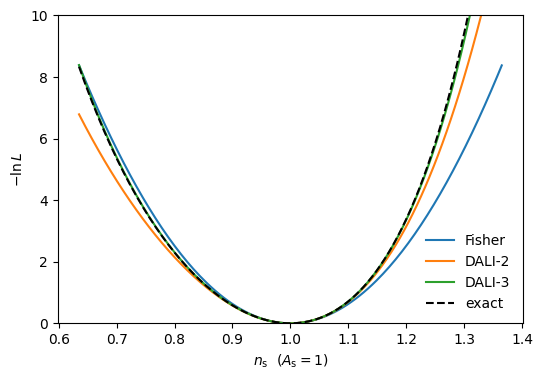

In [12]:
def exact_logpdf(theta):
    '''Exact Gaussian log-likelihood of the noiseless fiducial data vector.'''
    r = mean_spectrum(theta) - mean_spectrum(theta_fid)
    return -0.5 * np.einsum('...a,ab,...b->...', r, fm.C_inv, r)


ns = np.linspace(1 - 4 * sigma_ns, 1 + 4 * sigma_ns, 200)
grid = np.column_stack([np.full_like(ns, 1.0), ns])

fig, ax = plt.subplots(figsize=(6, 4))
for order, label, c in [(1, 'Fisher', 'C0'), (2, 'DALI-2', 'C1'), (3, 'DALI-3', 'C2')]:
    ax.plot(ns, -fm.dali_logpdf(grid, order=order), c=c, label=label)
ax.plot(ns, -exact_logpdf(grid), 'k--', label='exact')
ax.set_xlabel(r'$n_{\rm s}$  ($A_{\rm s} = 1$)')
ax.set_ylabel(r'$-\ln L$')
ax.set_ylim(0, 10)
ax.legend(frameon=False)
plt.show()

## 7. Fisher vs DALI vs the exact posterior

`sample(approx='dali', order=...)` draws equal-weight samples. `to_getdist` returns
weighted getdist samples. The default `method='importance'` reweights draws from the Fisher
Gaussian, with its covariance inflated by `inflate**2` (default 4). It prints a warning if
the effective sample size is low; `method='emcee'` runs an ensemble MCMC instead.

As the reference, we sample the exact likelihood with `psiphy.mcmc.MHSampler`.

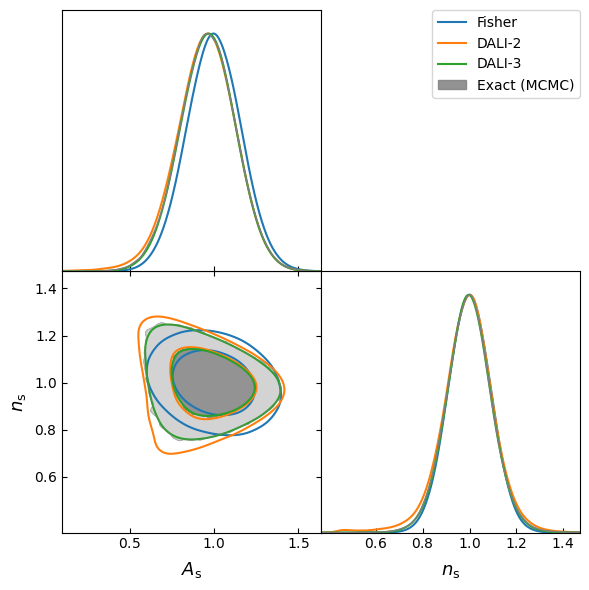

           mean(A_s)   sd(A_s)  skew(A_s)   mean(n_s)   sd(n_s)  skew(n_s)
Fisher         1.000     0.162       0.01       1.000     0.091       0.00
DALI-2         0.952     0.178      -0.29       0.991     0.115      -0.51
DALI-3         0.964     0.165      -0.02       0.998     0.096       0.02
Exact          0.963     0.168      -0.06       0.998     0.099       0.03

DALI importance sampling ESS: 88496 of 200000


In [13]:
def compare(fm, exact_logpdf, n_samples=200_000):
    '''getdist samples of the Fisher, DALI-2, DALI-3 and exact posteriors.'''
    kw = dict(n_samples=n_samples, label_names=label_names)
    out = {
        'Fisher': fm.to_getdist(approx='fisher', label='Fisher', **kw),
        'DALI-2': fm.to_getdist(order=2, label='DALI-2', **kw),
        'DALI-3': fm.to_getdist(order=3, label='DALI-3', **kw),
    }
    mh = MHSampler(exact_logpdf, n_walkers=32, vectorize=True)
    mh.run(fm.theta_fid, n_steps=20000, init_scale=1e-2)
    out['Exact'] = MCSamples(samples=mh.get_chain(flat=True, discard=2000), names=param_names,
                             labels=[label_names[p] for p in param_names], label='Exact (MCMC)')
    return out


def summary_table(samples):
    print(f"{'':8s}" + "".join(f"{f'mean({p})':>12s}{f'sd({p})':>10s}{f'skew({p})':>11s}" for p in param_names))
    for name, s in samples.items():
        w = s.weights / s.weights.sum()
        mean = w @ s.samples
        sd = np.sqrt(w @ (s.samples - mean)**2)
        skew = w @ ((s.samples - mean) / sd)**3
        print(f"{name:8s}" + "".join(f"{m:12.3f}{d:10.3f}{k:11.2f}" for m, d, k in zip(mean, sd, skew)))


def triangle(samples, fine_bins_2D=None):
    if fine_bins_2D is not None:   # long tails need a finer 2D grid
        for s in samples.values():
            s.updateSettings({'fine_bins_2D': fine_bins_2D})
    g = plots.get_subplot_plotter(width_inch=6)
    g.settings.legend_fontsize = 11
    g.triangle_plot(list(samples.values()), filled=[False, False, False, True],
                    contour_colors=['C0', 'C1', 'C2', 'gray'], contour_lws=[1.5, 1.5, 1.5, 1],
                    legend_loc='upper right')
    plt.show()


samples = compare(fm, exact_logpdf)
triangle(samples)
summary_table(samples)
print(f"\nDALI importance sampling ESS: {fm.dali_ess:.0f} of 200000")

The Fisher ellipse is centred on the fiducial values and is symmetric. The exact posterior
is shifted to lower $A_{\rm s}$ and is curved. DALI-2 captures the shift, but overshoots the
skewness and widens the contours. DALI-3 reproduces the exact means and widths to within a
few percent, and follows the curved contours.

## 8. Combining data blocks

`FisherMatrixDALI` supports the same block workflow as `FisherMatrix`. `fisher_blocks`
simulates each part of the data vector separately, with its own cache. With
`fisher_class=FisherMatrixDALI` and `dali_kw`, it also estimates the higher-order
derivatives of every block. `FisherMatrixDALI.joint` concatenates the blocks and keeps
their cross-covariance, for correlated blocks. `+` adds the log-likelihoods of independent
data sets.

We split the band powers into a low-$\ell$ and a high-$\ell$ block. Their noise is
independent, so `joint` and `+` should agree with each other and with the single forecast above.

In [14]:
from psiphy.forecasting import fisher_blocks


def block_simulator(theta, initial_seed, noise_seed, sl):
    return simulator(theta, initial_seed, noise_seed)[sl]


fms = fisher_blocks(
    block_simulator, theta_fid, param_names,
    blocks={'low ell': dict(sl=slice(0, 5)), 'high ell': dict(sl=slice(5, None))},
    fisher_class=FisherMatrixDALI,
    covariance_kw=dict(seeds=range(1, 51), noise_seeds=range(1, 11)),
    derivative_kw=dict(delta_frac=0.01, seeds=[1], noise_seed=0),
    dali_kw=dict(order=3, delta_frac=0.02, seeds=[1, 2], noise_seed=0),
)
for fb in fms.values():
    fb.compute()
joint = FisherMatrixDALI.joint(list(fms.values()), verbose=False).compute()
added = fms['low ell'] + fms['high ell']

theta_test = fm.sample(1000, order=3)
for name, f in [('joint', joint), ('low + high', added)]:
    diff = np.abs(f.dali_logpdf(theta_test) - fm.dali_logpdf(theta_test)).max()
    print(f"{name:10s}: max |ln L - ln L(single forecast)| = {diff:.3f}")

print(f"\n{'':12s}{'sd(A_s)':>10s}{'sd(n_s)':>10s}   (DALI-3)")
for name, f in [('joint', joint), ('low + high', added), ('single', fm)]:
    sd = f.sample(100_000, order=3).std(axis=0)
    print(f"{name:12s}{sd[0]:10.3f}{sd[1]:10.3f}")

joint     : max |ln L - ln L(single forecast)| = 0.000
low + high: max |ln L - ln L(single forecast)| = 0.274

               sd(A_s)   sd(n_s)   (DALI-3)
joint            0.165     0.097


low + high       0.164     0.099


single           0.166     0.098


`joint` reproduces the single forecast exactly, because it uses the same simulations and
the same covariance. `+` differs slightly, because it drops the sample cross-covariance between
the blocks. Here that is only noise; for correlated blocks it would be real, so use `joint` for those.

Apply DALI to the combination, not to the blocks one at a time. On its own, each block constrains
$n_{\rm s}$ so weakly that its Taylor expansion would not converge (see the next section).

## 9. When the expansion breaks down

DALI is a Taylor series, so it can only be trusted while the series converges over the
posterior. With the noise doubled to 1.0, $\sigma(n_{\rm s})$ grows to about 0.18, and
$\delta n_{\rm s} \ln(\ell/\ell_{\rm pivot})$ reaches 1.6 at $3\sigma$. The truncated
exponential is then a poor approximation:

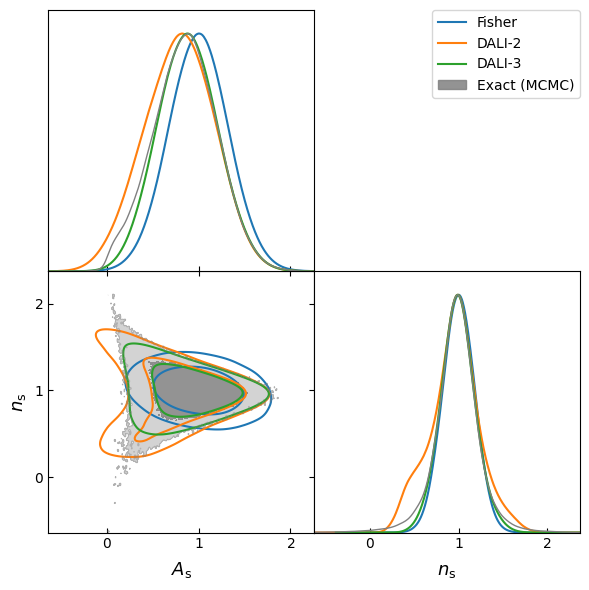

           mean(A_s)   sd(A_s)  skew(A_s)   mean(n_s)   sd(n_s)  skew(n_s)
Fisher         1.000     0.324       0.00       1.000     0.182      -0.02
DALI-2         0.788     0.382      -0.08       0.951     0.285      -0.06
DALI-3         0.882     0.329       0.07       0.992     0.199       0.10


Exact          0.852     0.349       0.01       0.978     0.269      -0.31


In [15]:
fm_hi = FisherMatrixDALI(make_simulator(1.0), theta_fid, param_names, verbose=False)
fm_hi.estimate_covariance(seeds=range(1, 51), noise_seeds=range(1, 11))
fm_hi.estimate_derivatives(delta_frac=0.01, seeds=[1], noise_seed=0)
fm_hi.estimate_dali_derivatives(order=3, delta_frac=0.02, seeds=[1, 2], noise_seed=0)
fm_hi.compute();


def exact_logpdf_hi(theta):
    r = mean_spectrum(theta) - mean_spectrum(theta_fid)
    return -0.5 * np.einsum('...a,ab,...b->...', r, fm_hi.C_inv, r)


samples_hi = compare(fm_hi, exact_logpdf_hi)
triangle(samples_hi, fine_bins_2D=1024)
summary_table(samples_hi)

The exact posterior now has a long tail towards low $n_{\rm s}$ and $A_{\rm s}$ (hence its large skewness).
DALI-2 and DALI-3 disagree with each other, and neither matches it.
Comparing two orders is a cheap check: if DALI-2 and DALI-3 differ a lot, the expansion has
not converged. Sample the full likelihood or use simulation-based inference instead.

## Summary

| Step | Method |
|------|--------|
| Create object | `FisherMatrixDALI(simulator, theta_fid, param_names)` |
| Covariance, first derivatives, Fisher | as for `FisherMatrix` |
| Higher-order derivatives | `fm.estimate_dali_derivatives(order=2 or 3, delta_frac, seeds, accuracy)` |
| Noise check | warnings, `fm.dali_snr`, `fm.dali_noise_1sigma` |
| Likelihood | `fm.dali_logpdf(theta, order)`, `fm.dali_tensors()` |
| Posterior | `fm.sample(approx='dali')`, `fm.to_getdist(approx='dali')` |
| Blocks | `fisher_blocks(..., fisher_class=FisherMatrixDALI, dali_kw=...)`, `FisherMatrixDALI.joint(blocks)`, `fm_a + fm_b` |
| Save / load | `fm.save('results.npz')` / `FisherMatrixDALI.load('results.npz')` |

Practical notes:
- Use a larger `delta_frac` for the higher derivatives than for the first ones, and check it with a sweep as in section 4.
- Make sure the simulator gives the same realisation for the same seeds at every `theta`; without that, the higher derivatives are noise.
- The covariance is taken as parameter-independent, as in `FisherMatrix`.
- Compare DALI-2 with DALI-3. If they disagree, the Taylor expansion is not reliable for this posterior.